# Latvian company credit risk: the walkthrough

Every figure in the README is printed by a cell below, from the full files in `data/raw/` and from
what the full chain wrote into `_localrun/bucket/`. Section 11 also reads two runs of the chain on
the committed sample, one per cadence, and the Glue 5.0 image's run:

```bash
python local-development/fetch_raw_data.py
python local-development/run_chain.py --data raw
python local-development/run_chain.py --data sample --root _localrun/sample-quarter
python local-development/run_chain.py --data sample --cadence year --root _localrun/sample-year
./local-docker-development.sh
```

The source files are read only through `stage_batches.read_source`, which parses the allow-listed
columns and nothing else, so no name, address or debtor identity column is loaded here either.

In [1]:
import json
import os
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
PROJECT = Path.cwd()
for path in (PROJECT, PROJECT / "glue-jobs", PROJECT / "local-development"):
    sys.path.insert(0, str(path))

from company_credit import analysis, config, metrics, panel
from stage_batches import FILES, read_companies, read_source

RAW = PROJECT / "data" / "raw"
BUCKET = PROJECT / "_localrun" / "bucket"
MODEL = BUCKET / "results" / "model"
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)


def result(name, bucket=BUCKET):
    return pd.read_csv(bucket / "results" / "model" / f"{name}.csv")


manifest = json.loads((RAW / "manifest.json").read_text())
print("retrieved", manifest["retrieved"][:10])
for name, entry in manifest["files"].items():
    if "rows" in entry:
        print(f"{name:48s} {entry['bytes'] / 1e6:7.1f} MB {entry['rows']:>11,} rows  "
              f"published {entry['last_modified'][:10]}")
    else:
        print(f"{name:48s} {entry['bytes'] / 1e3:7.1f} kB  the code sheet")
for source, name in FILES.items():
    with open(RAW / name, "rb") as handle:
        bom = handle.read(3) == b"\xef\xbb\xbf"
    print(f"{name:48s} starts with a byte-order mark: {bom}")

retrieved 2026-11-02
financial_statements.csv                           206.0 MB   1,986,118 rows  published 2026-11-01
balance_sheets.csv                                 143.2 MB   1,861,769 rows  published 2026-11-01
income_statements.csv                              149.9 MB   1,752,742 rows  published 2026-11-01
cash_flow_statements.csv                            21.1 MB     181,096 rows  published 2026-11-01
insolvency_legal_person_proceeding.csv               6.2 MB      18,053 rows  published 2026-11-01
register.csv                                       128.9 MB     489,966 rows  published 2026-11-01
insolvency_proceeding_kolonnu_apzimejumi.xlsx       19.6 kB  the code sheet
register.csv                                     starts with a byte-order mark: False
insolvency_legal_person_proceeding.csv           starts with a byte-order mark: False
financial_statements.csv                         starts with a byte-order mark: False
balance_sheets.csv                               st

## 1. Who counts: companies only

The register's type decides. Individual merchants (IK), individual and family enterprises, farms
and fishing holdings carry their owners' names and are dropped on read, with associations,
foundations, churches, unions, parties, the media register and foreign branches.

In [2]:
for source in ("register", "insolvency_legal_person_proceeding"):
    header = pd.read_csv(RAW / FILES[source], sep=";", nrows=0).columns
    allowed = set(config.SOURCE_COLUMNS[source])
    print(f"{FILES[source]}: {len(header)} columns in the header, {len(allowed & set(header))} "
          f"allow-listed and read, {len(set(header) - allowed)} never parsed")

register_all = read_source(RAW, "register")
register = read_companies(RAW)
companies = set(register.regcode)
print(f"register entities {len(register_all):,} | companies {len(register):,}")
print(register.type.value_counts().to_string())
print(f"terminated companies: {register.terminated.notna().sum():,}")

statements_all = read_source(RAW, "financial_statements")
statements = statements_all[statements_all.legal_entity_registration_number.isin(companies)].copy()
proceedings_all = read_source(RAW, "insolvency_legal_person_proceeding")
proceedings = proceedings_all[proceedings_all.debtor_registration_number.isin(companies)].copy()
print(f"statements {len(statements_all):,} -> companies' {len(statements):,} "
      f"for {statements.legal_entity_registration_number.nunique():,} companies")
print(f"proceedings {len(proceedings_all):,} -> companies' {len(proceedings):,} "
      f"for {proceedings.debtor_registration_number.nunique():,} debtors")

register.csv: 21 columns in the header, 5 allow-listed and read, 16 never parsed
insolvency_legal_person_proceeding.csv: 23 columns in the header, 8 allow-listed and read, 15 never parsed


register entities 489,966 | companies 347,053
type
SIA    339247
KB       3770
AS       2448
PS       1128
KS        450
SE         10
terminated companies: 203,938


statements 1,986,118 -> companies' 1,708,249 for 221,741 companies
proceedings 18,053 -> companies' 17,548 for 15,471 debtors


## 2. When accounts exist: `created_at` and the embargo

`created_at` looks like a filing time. For every statement published before 18 January 2021 it is
not: those carry a stamp from the Register's bulk load.

In [3]:
created = pd.to_datetime(statements_all.created_at, format="mixed")
ended = pd.to_datetime(statements_all.year_ended_on)
fiscal = statements_all.year.astype(int)
bulk = created < pd.Timestamp(config.BULK_LOAD_END)
daily = created[bulk].dt.normalize().value_counts().sort_index()
heavy = daily[daily > 3000]
print(f"stamped before {config.BULK_LOAD_END}: {bulk.sum():,} statements, "
      f"{created[bulk].min().date()} to {created[bulk].max().date()}, on {len(daily)} days; "
      f"fiscal years {fiscal[bulk].min()}-{fiscal[bulk].max()}, "
      f"{(fiscal[bulk] <= 2019).mean():.2%} of them FY2019 or earlier")
print(f"days with more than 3,000 stamps: {len(heavy)}, {heavy.index.min().date()} to "
      f"{heavy.index.max().date()}, {heavy.sum():,} statements, median {int(heavy.median()):,} a day")
print(f"stamped from {config.BULK_LOAD_END}: {(~bulk).sum():,}")
after = created[~bulk].dt.normalize().value_counts()
print(f"busiest day since: {after.max():,} ({after.idxmax().date()})")
lag = (created - ended).dt.days
by_year = pd.DataFrame({
    "statements": fiscal.value_counts().sort_index(),
    "bulk_stamped": fiscal[bulk].value_counts(),
    "median_days_to_created_at": lag.groupby(fiscal).median(),
}).fillna(0).astype(int)
print(by_year.loc[2008:2025].to_string())

stamped before 2021-01-18: 1,152,314 statements, 2020-08-11 to 2021-01-17, on 160 days; fiscal years 2006-2020, 99.87% of them FY2019 or earlier
days with more than 3,000 stamps: 73, 2020-08-12 to 2021-01-14, 1,113,708 statements, median 17,534 a day
stamped from 2021-01-18: 833,804
busiest day since: 10,834 (2024-03-11)


      statements  bulk_stamped  median_days_to_created_at
year                                                     
2008       15892         15892                       4242
2009       30213         30213                       3880
2010       55642         55642                       3520
2011       76278         76278                       3159
2012       97677         97676                       2798
2013      113118        113116                       2439
2014      122149        122053                       2080
2015      112261        112009                       1721
2016      132585        131996                       1396
2017      135326        134238                       1039
2018      136139        133451                        681
2019      136715        128217                        324
2020      137141          1482                        172
2021      137266             0                        185
2022      138010             0                        149
2023      1380

In [4]:
own = statements.assign(created=pd.to_datetime(statements.created_at, format="mixed"),
                        ended=pd.to_datetime(statements.year_ended_on))
group = (own.source_type.isin(config.CONSOLIDATED_SOURCE_TYPES)
         | own.source_schema.isin(config.CONSOLIDATED_SCHEMAS))
own = own[~group]
december = own.ended.dt.strftime("%m-%d") == "12-31"
print(f"statements ending 31 December: all {(ended.dt.strftime('%m-%d') == '12-31').mean():.1%}, "
      f"companies' own {december.mean():.1%}")
real = own[(own.created >= pd.Timestamp(config.BULK_LOAD_END)) & december
           & own.year.astype(int).between(2020, 2024)]
days = (real.created - real.ended).dt.days
filed = pd.DataFrame({f"by {label}": (days <= limit).groupby(real.year).mean()
                      for label, limit in [("30 Apr", 120), ("30 Jun", 181), ("31 Aug", 243),
                                           ("30 Sep", 273)]})
filed["median days"] = days.groupby(real.year).median()
filed["statements"] = days.groupby(real.year).size()
print("companies' own accounts for 31 December year ends, share filed by:")
print(filed.round(3).to_string())

statements ending 31 December: all 99.2%, companies' own 99.1%


companies' own accounts for 31 December year ends, share filed by:
      by 30 Apr  by 30 Jun  by 31 Aug  by 30 Sep  median days  statements
year                                                                     
2020      0.350      0.507      0.901      0.931        180.0      111893
2021      0.269      0.451      0.876      0.916        195.0      112743
2022      0.369      0.845      0.920      0.929        142.0      112967
2023      0.332      0.853      0.922      0.932        145.0      113330
2024      0.332      0.884      0.939      0.951        144.0      112776


## 3. Duplicates, group accounts, currency and rounding

In [5]:
print(f"group (consolidated) statements dropped: {group.sum():,}")
per_year = own.groupby(["legal_entity_registration_number", "year"]).size()
periods = (own.assign(period=own.year_started_on.astype(str) + "/" + own.year_ended_on.astype(str))
           .groupby(["legal_entity_registration_number", "year"]).period.nunique())
multi = per_year[per_year > 1].index
print(f"company-years {len(per_year):,}; with more than one statement {len(multi):,}: "
      f"{(periods[multi] == 1).sum():,} for one period, {(periods[multi] > 1).sum():,} "
      f"for two periods in one fiscal year")
print(pd.crosstab(statements_all.year.astype(int), statements_all.currency).loc[2012:2015].to_string())
print(pd.crosstab(statements_all.rounded_to_nearest, statements_all.currency).to_string())

group (consolidated) statements dropped: 4,412


company-years 1,702,893; with more than one statement 936: 183 for one period, 753 for two periods in one fiscal year


currency     EUR     LVL
year                    
2012           0   97677
2013         280  112838
2014      122149       0
2015      112261       0


currency                EUR     LVL
rounded_to_nearest                 
ONES                1597394  388591
THOUSANDS               133       0


In [6]:
balances = read_source(RAW, "balance_sheets")[["statement_id", "total_assets"]]
figures = statements_all[["id", "legal_entity_registration_number", "year", "rounded_to_nearest"]].merge(
    balances, left_on="id", right_on="statement_id")
figures["total_assets"] = figures.total_assets.astype(float)
figures["year"] = figures.year.astype(int)
ones = figures[figures.rounded_to_nearest == "ONES"]
pivot = ones[ones.year.isin([2013, 2014])].pivot_table(
    index="legal_entity_registration_number", columns="year", values="total_assets",
    aggfunc="last").dropna()
pivot = pivot[(pivot[2013] > 10000) & (pivot[2014] > 10000)]
print(f"median FY2014 / FY2013 total assets, {len(pivot):,} companies: "
      f"{(pivot[2014] / pivot[2013]).median():.4f} | 1 / {config.LVL_PER_EUR} = "
      f"{1 / config.LVL_PER_EUR:.4f}")

# A THOUSANDS statement against the same company's ONES statement for the year before or after.
thousands = figures[figures.rounded_to_nearest == "THOUSANDS"]
neighbour = ones[ones.year >= 2014].groupby(["legal_entity_registration_number", "year"]).total_assets.last()
ratios = []
for row in thousands.itertuples():
    for year in (row.year - 1, row.year + 1):
        base = neighbour.get((row.legal_entity_registration_number, year))
        if base and base > 0 and row.total_assets > 0:
            ratios.append(row.total_assets * 1000 / base)
            break
print(f"THOUSANDS statements: {len(thousands)}; with a ONES neighbour year: {len(ratios)}; "
      f"median (total assets x 1000) / neighbour's total assets: {np.median(ratios):.3f}")

median FY2014 / FY2013 total assets, 46,681 companies: 1.4207 | 1 / 0.702804 = 1.4229


THOUSANDS statements: 133; with a ONES neighbour year: 54; median (total assets x 1000) / neighbour's total assets: 1.146


## 4. What a default is

The first start of a non-dismissed insolvency, legal-protection or out-of-court legal-protection
proceeding. The excluded codes are the dismissal and left-without-action codes of the Register's
own code sheet.

In [7]:
glossary = pd.read_excel(RAW / "insolvency_proceeding_kolonnu_apzimejumi.xlsx",
                         sheet_name="proceeding_resulotion_type", header=None, skiprows=1)
glossary.columns = ["code", "lv", "en"]
pd.set_option("display.max_colwidth", 80)
print(glossary[glossary.code.isin(config.DISMISSED)][["code", "en"]].to_string(index=False))

p = proceedings.rename(columns={"debtor_registration_number": "regcode"})
for column in ("proceeding_started_on", "proceeding_ended_on", "entry_created_on"):
    p[column] = pd.to_datetime(p[column])
print(p.proceeding_form.value_counts().to_string())
dismissed = p.proceeding_resolution_type.isin(config.DISMISSED)
print(f"dismissed or left without action: {dismissed.sum():,}",
      p[dismissed].proceeding_resolution_type.value_counts().to_dict())
m01 = p[p.proceeding_resolution_type == "M01"]
print(f"M01 starts {m01.proceeding_started_on.dt.year.min()}-{m01.proceeding_started_on.dt.year.max()}, "
      f"median {int((m01.proceeding_ended_on - m01.proceeding_started_on).dt.days.median())} days "
      f"from application to dismissal")
entry = (p.entry_created_on.dt.normalize() - p.proceeding_started_on).dt.days
print("entry_created_on minus start, median days by start year:")
print(entry.groupby(p.proceeding_started_on.dt.year).median().astype(int).to_dict())
print(f"open today: {p.proceeding_ended_on.isna().sum():,}; newest entry_created_on "
      f"{p.entry_created_on.max().date()}")

code                                                                           en
 A09  application for out of court legal protection proceeding has been dismissed
 A12                                           Application is left without action
 M01                    Application for insolvency proceedings has been dismissed
 M12                                           Application is left without action
 T07                 Dismissal of the application for legal protection proceeding
 T18 Application for out of court legal protection proceedings has been dismissed
 T19                                           Application is left without action
proceeding_form
INSOLVENCY                       14987
LEGAL_PROTECTION                  2111
OUT_OF_COURT_LEGAL_PROTECTION      450
dismissed or left without action: 908 {'M01': 649, 'T18': 189, 'T07': 35, 'A09': 29, 'T19': 6}
M01 starts 2008-2012, median 38 days from application to dismissal
entry_created_on minus start, median days by star

In [8]:
first = panel.first_defaults(p)
first_insolvency = panel.first_defaults(p, insolvency_only=True)
kept = p[~dismissed].sort_values(["proceeding_started_on", "proceeding_id"]).groupby("regcode").first()
protection = kept[kept.proceeding_form != "INSOLVENCY"]
defaults = pd.DataFrame({
    "first_default": first.dt.year.value_counts(),
    "via_protection": protection.proceeding_started_on.dt.year.value_counts(),
    "insolvency_only": first_insolvency.dt.year.value_counts(),
}).fillna(0).astype(int).sort_index()
print(defaults.T.to_string())
print(f"companies with a default {len(first):,}; first via protection {len(protection):,}, "
      f"of which later insolvent {protection.index.isin(first_insolvency.index).sum():,}")

proceeding_started_on  2008  2009  2010  2011  2012  2013  2014  2015  2016  2017  2018  2019  2020  2021  2022  2023  2024  2025  2026
first_default          1344  2253  2369   816   885   877   963   802   747   612   625   583   398   280   353   277   344   312   270
via_protection            8    56   158    91   109   170   175   109   110   113   127   108    90    72   110    82   118    99    86
insolvency_only        1338  2206  2298   803   866   802   937   773   708   567   579   547   361   240   300   234   279   263   217
companies with a default 15,110; first via protection 1,991, of which later insolvent 1,199


## 5. The replay: dated batches, and what each MERGE restated

Read back from each Delta table's own history: the batch date and counts travel in the commit's
`userMetadata`, and Delta's operation metrics give the inserts and updates.

In [9]:
chain = json.loads((BUCKET / "results" / "chain.json").read_text())
print("chain:", chain["data"], chain["cadence"], chain["seconds"])
batches = result("batches")
print(f"{batches.batch_date.nunique()} batch dates, {batches.batch_date.min()} to {batches.batch_date.max()}")
summary = batches.groupby("table").agg(batches=("batch_date", "size"), rows=("rows", "sum"),
                                       inserted=("inserted", "sum"), restated=("restated", "sum"),
                                       unchanged=("unchanged", "sum"),
                                       duplicates_dropped=("duplicates_dropped", "sum"),
                                       group_dropped=("consolidated_dropped", "sum"))
summary["restatement_share"] = (summary.restated / summary.rows).round(4)
print(summary.to_string())
later = batches[batches.version > 0]
print("per-batch restatement share, every batch after the first:")
print(later.groupby("table").restatement_share.describe()[["min", "50%", "max"]].round(3).to_string())

chain: raw quarter {'stage': 87, 'companies': 310, 'proceedings': 263, 'statements': 505, 'model': 397, 'chain': 1562}
73 batch dates, 2008-12-31 to 2026-11-01
             batches     rows  inserted  restated  unchanged  duplicates_dropped  group_dropped  restatement_share
table                                                                                                             
companies         73   498530    347053    151477          0                   0              0             0.3038
proceedings       73    33303     17548     15755          0                   0              0             0.4731
statements        72  1703441   1702893       547          1                 396           4412             0.0003
per-batch restatement share, every batch after the first:
               min    50%    max
table                           
companies    0.109  0.432  0.830
proceedings  0.252  0.507  0.684
statements   0.000  0.000  0.104


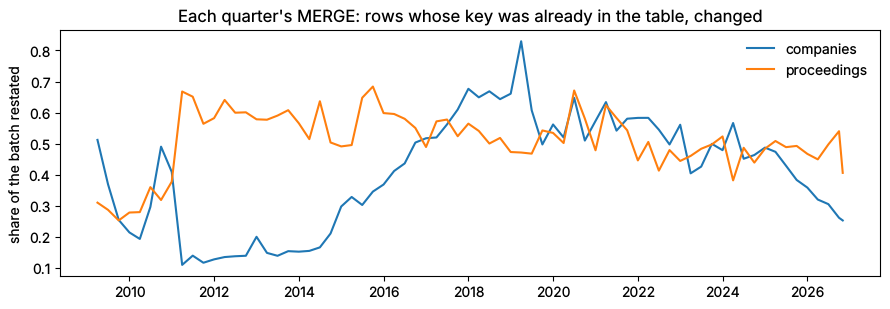

In [10]:
fig, ax = plt.subplots(figsize=(9, 3.2))
for table in ("companies", "proceedings"):
    part = later[later.table == table]
    ax.plot(pd.to_datetime(part.batch_date), part.restatement_share, label=table)
ax.set_ylabel("share of the batch restated")
ax.set_title("Each quarter's MERGE: rows whose key was already in the table, changed")
ax.legend(frameon=False)
fig.tight_layout()

### Time travel against today's table with a date filter

On the eve of four observation dates, the proceedings table read at the version of that day's
batch, against today's table filtered to the proceedings entered before the observation date. The
filter brings back the right rows, but each with today's end date and resolution.

In [11]:
import lakehouse as lh

# The JVM writes its start-up chatter to the process's own stdout and stderr, which it keeps
# for its whole life; start it with both pointed at /dev/null so none of it lands in the outputs.
saved, devnull = (os.dup(1), os.dup(2)), os.open(os.devnull, os.O_WRONLY)
os.dup2(devnull, 1)
os.dup2(devnull, 2)
try:
    spark = lh.build_session("walkthrough", local=True, driver_memory="4g")
finally:
    os.dup2(saved[0], 1)
    os.dup2(saved[1], 2)

path = str(BUCKET / "lakehouse-dwh" / "proceedings")
versions = lh.batch_versions(spark, path)
today = spark.read.format("delta").load(path).toPandas()
rows = []
for year in (2012, 2016, 2020, 2024):
    obs = pd.Timestamp(panel.observation_date(year))
    eve = panel.eve(obs.date())
    then = lh.read_as_of(spark, path, versions, eve).toPandas()
    filtered = today[pd.to_datetime(today.entry_created_on) < obs]
    open_then = then[then.proceeding_ended_on.isna()].proceeding_id
    now = filtered.set_index("proceeding_id").loc[open_then]
    rows.append({"eve": eve, "version": lh.version_as_of(versions, eve), "rows_as_of": len(then),
                 "open_as_of": len(open_then), "rows_filtered": len(filtered),
                 "open_in_filtered": int(filtered.proceeding_ended_on.isna().sum()),
                 "open_then_dismissed_since": int(now.proceeding_resolution_type.isin(config.DISMISSED).sum())})
print(pd.DataFrame(rows).to_string(index=False))

       eve  version  rows_as_of  open_as_of  rows_filtered  open_in_filtered  open_then_dismissed_since
2012-09-30       15        8448        2712           8448                 2                          7
2016-09-30       31       12473        1165          12473                12                          4
2020-09-30       47       15162         749          15162                43                          0
2024-09-30       63       16722         772          16722               293                          5


## 6. The company-year rows

Built by the model job, one observation date at a time, from the three tables read as of the eve
of 1 October and the insolvency register read as of the eve of the horizon's end.

In [12]:
rows = pd.read_parquet(BUCKET / "results" / "pd_rows")
run = result("run").iloc[0]
print(f"as of {run.as_of}: {run.rows:,} company-years, observation years {run.first_year}-"
      f"{run.last_year}, live year {run.live_year}")
coverage = result("coverage")
print(coverage.round(3).to_string(index=False))
for name, (a, b) in analysis.WINDOWS.items():
    part = coverage[coverage.observation_year.between(a, b)]
    print(f"{name} {a}-{b}: PD covers {part.covered.sum() / part.live.sum():.1%} of live "
          f"company-years and {part.covered_defaults.sum() / part.defaults.sum():.1%} of their defaults")

as of 2026-10-30: 2,354,336 company-years, observation years 2009-2025, live year 2026
 observation_year   live  covered  defaults  covered_defaults  previous_year_accounts  covered_share  defaulter_coverage
             2009 101145    15142      2483               446                      28          0.150               0.180
             2010 104296    30715      1121               391                    2131          0.294               0.349
             2011 117077    55570       869               457                    3316          0.475               0.526
             2012 131181    75138       886               592                    3935          0.573               0.668
             2013 144231    87714       910               678                    4489          0.608               0.745
             2014 155950   100943       899               764                    4986          0.647               0.850
             2015 163214   108701       741               653     

In [13]:
rows["window"] = analysis.window_of(rows.observation_year)
obs_dates = pd.to_datetime(rows.observation_year.astype(str) + "-10-01")
revealed = (rows.y == 1) & (pd.to_datetime(rows.default_start) < obs_dates)
print(f"defaults started before the observation date and entered after it: {int(revealed.sum())} "
      f"of {int(rows.y.sum()):,}")
flips = result("dismissal_flips")
print(f"labelled defaults that today's register would not label (undecided at the horizon's "
      f"end, dismissed since): {flips.dismissed_since.sum()} of {flips.defaults.sum():,}")
print(rows.groupby("window").agg(rows=("y", "size"), defaults=("y", "sum"),
                                 covered=("covered", "sum")).to_string())
print("default rate by window, not scored (False) and scored (True):")
print(rows.groupby(["window", "covered"]).y.mean().unstack().round(4).to_string())

defaults started before the observation date and entered after it: 119 of 12,133
labelled defaults that today's register would not label (undecided at the horizon's end, dismissed since): 105 of 12,133


             rows  defaults  covered
window                              
test       672328      1613   560508
train     1247720      9190   700965
validate   434288      1330   346494
default rate by window, not scored (False) and scored (True):


covered    False   True 
window                  
test      0.0014  0.0026
train     0.0074  0.0073
validate  0.0009  0.0036


## 7. The scorecard

In [14]:
print(result("iv").round(4).to_string(index=False))
print(result("dropped").to_string(index=False))
print(result("coefficients").round(4).to_string(index=False))
print(result("accounts_lag").round(4).to_string(index=False))

  characteristic     iv  bins  in_model
    total_assets 0.5369    11      True
    net_turnover 0.5208     9      True
    equity_ratio 0.5040    12      True
      cash_ratio 0.3936    12      True
   current_ratio 0.3882    12      True
       employees 0.3544     7      True
 interest_burden 0.2481     6      True
return_on_assets 0.1589    12      True
        firm_age 0.0395    10     False
      legal_form 0.0319     4      True
    accounts_lag 0.0157     2      True
  asset_turnover 0.0088    10     False
characteristic    reason
asset_turnover IV 0.0088
      firm_age   p 0.473
            term    coef  std_err         z  p_value
           const -4.9508   0.0180 -275.1397      0.0
    equity_ratio -0.6366   0.0323  -19.7192      0.0
   current_ratio -0.3933   0.0279  -14.0931      0.0
return_on_assets -0.8553   0.0542  -15.7885      0.0
      cash_ratio -0.5923   0.0312  -18.9819      0.0
 interest_burden -0.1844   0.0390   -4.7251      0.0
    total_assets -0.3589   0.0321 

In [15]:
# The numpy logit against statsmodels, on the training rows and the selected WoE columns.
import time
import statsmodels.api as sm
from company_credit import logit, scorecard

train = analysis.prepare(rows.drop(columns="window"))[1]
train = train[train.window == "train"]
card = scorecard.fit(train)
X, y, groups = card.woe_columns(train), train.y.to_numpy(), train.regcode.to_numpy()
started = time.monotonic()
ours = logit.fit(X.to_numpy(), y, groups=groups, names=list(X.columns))
print(f"numpy logit: {len(train):,} rows, {train.regcode.nunique():,} companies, {X.shape[1]} terms, "
      f"{ours.iterations} Newton steps, {time.monotonic() - started:.1f} s")
theirs = sm.Logit(y, X).fit(disp=0, cov_type="cluster", cov_kwds={"groups": pd.factorize(groups)[0]})
naive = sm.Logit(y, X).fit(disp=0)
print(f"against statsmodels: max |coef difference| {np.abs(ours.params - theirs.params.to_numpy()).max():.1e}, "
      f"max |clustered s.e. difference| {np.abs(ours.bse - theirs.bse.to_numpy()).max():.1e}")
ratio = pd.Series(ours.bse / naive.bse.to_numpy(), index=X.columns).drop("const")
print(f"clustered over naive s.e.: {ratio.min():.2f}-{ratio.max():.2f}, wider for {(ratio > 1).sum()} of {len(ratio)}")

numpy logit: 700,965 rows, 150,781 companies, 11 terms, 8 Newton steps, 1.3 s


against statsmodels: max |coef difference| 3.3e-16, max |clustered s.e. difference| 8.3e-17
clustered over naive s.e.: 0.72-1.12, wider for 8 of 10


In [16]:
# The previous-year accounts' coefficient and its clustered p-value, unrounded.
coef = result("coefficients").set_index("term")
print(f"accounts_lag coef {coef.coef['accounts_lag']:.3f}, p {coef.p_value['accounts_lag']:.1e}")

accounts_lag coef -0.557, p 8.4e-08


In [17]:
windows = result("windows")
print(windows[["window", "n", "defaults", "default_rate", "auc", "auc_low", "auc_high", "gini", "ks",
               "benchmark_auc", "benchmark_low", "benchmark_high"]].round(4).to_string(index=False))
print("without accounts_lag:")
print(result("without_accounts_lag")[["window", "auc", "auc_low", "auc_high"]].round(4).to_string(index=False))
print("insolvency-only label, same score:")
print(result("insolvency_only")[["window", "defaults", "auc", "auc_low", "auc_high"]].round(4).to_string(index=False))
print("trained on 2011-17 only:")
print(result("train_2011")[["window", "auc", "auc_low", "auc_high", "pd_ttc", "pd_validation",
                            "default_rate"]].round(4).to_string(index=False))

  window      n  defaults  default_rate    auc  auc_low  auc_high   gini     ks  benchmark_auc  benchmark_low  benchmark_high
   train 700965      5149        0.0073 0.8008   0.7949    0.8066 0.6015 0.4531         0.6465         0.6406          0.6524
validate 346494      1253        0.0036 0.8027   0.7905    0.8149 0.6054 0.4547         0.6514         0.6400          0.6629
    test 560508      1455        0.0026 0.8176   0.8066    0.8285 0.6351 0.4822         0.6542         0.6437          0.6647
without accounts_lag:
  window    auc  auc_low  auc_high
    test 0.8151   0.8042    0.8260
   train 0.8001   0.7942    0.8060
validate 0.8012   0.7889    0.8135
insolvency-only label, same score:
  window  defaults    auc  auc_low  auc_high
    test      1043 0.8009   0.7877    0.8141
   train      4469 0.7903   0.7840    0.7967
validate      1013 0.7898   0.7761    0.8035
trained on 2011-17 only:
  window    auc  auc_low  auc_high  pd_ttc  pd_validation  default_rate
    test 0.8143   0.80

In [18]:
years = result("years")
level = result("level").iloc[0]
print(f"validation shift on the log-odds: {level.validation_shift:.4f}")
print(years[["observation_year", "n", "defaults", "observed", "pd_ttc", "pd_validation", "oe_ttc",
             "oe_validation", "auc", "benchmark_auc", "psi"]].round(4).to_string(index=False))
print(windows[["window", "default_rate", "pd_ttc", "pd_validation"]].round(4).to_string(index=False))

validation shift on the log-odds: -0.5056
 observation_year      n  defaults  observed  pd_ttc  pd_validation  oe_ttc  oe_validation    auc  benchmark_auc    psi
             2009  15142       446    0.0295  0.0105         0.0064  2.7923         4.5796 0.7797         0.6469 0.0932
             2010  30715       391    0.0127  0.0102         0.0062  1.2427         2.0389 0.7707         0.6595 0.0941
             2011  55570       457    0.0082  0.0090         0.0055  0.9188         1.5087 0.7804         0.6491 0.0361
             2012  75138       592    0.0079  0.0081         0.0049  0.9727         1.5982 0.8014         0.6431 0.0091
             2013  87714       678    0.0077  0.0075         0.0046  1.0306         1.6938 0.7995         0.6529 0.0009
             2014 100943       764    0.0076  0.0069         0.0042  1.1039         1.8152 0.7911         0.6683 0.0033
             2015 108701       653    0.0060  0.0068         0.0041  0.8853         1.4558 0.8050         0.6513 0.004

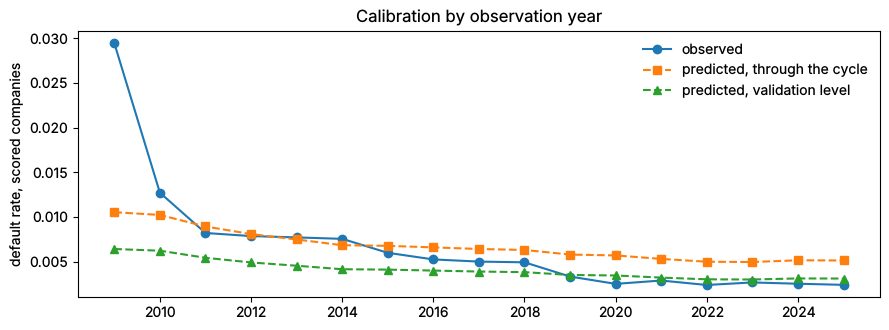

In [19]:
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(years.observation_year, years.observed, "o-", label="observed")
ax.plot(years.observation_year, years.pd_ttc, "s--", label="predicted, through the cycle")
ax.plot(years.observation_year, years.pd_validation, "^--", label="predicted, validation level")
ax.set_ylabel("default rate, scored companies")
ax.set_title("Calibration by observation year")
ax.legend(frameon=False)
fig.tight_layout()

## 8. What the bulk load costs

The test years scored twice: with real filing dates, and with every statement dated the bulk way.
The job's table first; then the same fit is repeated here from the rows it wrote, which must give
the job's AUCs, and the comparison is redone on the companies scored on last year's accounts only.

In [20]:
print(result("bulk_dating").round(4).T.to_string())
bulk_rows = pd.read_parquet(BUCKET / "results" / "pd_rows_bulk_dated")
refit = analysis.run(rows.drop(columns="window"), bulk_rows=bulk_rows)
print("refitted here:", refit["windows"].set_index("window").auc.round(4).to_dict())
print("the job's:    ", windows.set_index("window").auc.round(4).to_dict())

                                   0
real_rows                560508.0000
real_defaults              1455.0000
real_auc                      0.8176
real_defaulter_coverage       0.9020
bulk_rows                574547.0000
bulk_defaults              1502.0000
bulk_auc                      0.8182
bulk_defaulter_coverage       0.9312
added_rows                14084.0000
late_filers               39570.0000
late_defaults               162.0000
late_rate                     0.0041
on_time_rate                  0.0025


refitted here: {'train': 0.8008, 'validate': 0.8027, 'test': 0.8176}
the job's:     {'train': 0.8008, 'validate': 0.8027, 'test': 0.8176}


In [21]:
card = refit["card"]
keys = ["regcode", "observation_year"]
real_test = analysis.score_rows(card, analysis.prepare(rows[rows.window == "test"].drop(columns="window"))[1])
bulk_test = analysis.score_rows(card, analysis.prepare(bulk_rows)[1])
added = bulk_test.merge(real_test[keys].assign(real=True), on=keys, how="left")
added = added[added.real.isna()]
print(f"company-years scored only when bulk-dated: {len(added):,}, default rate {added.y.mean():.2%}; "
      f"scored with real dates: {len(real_test):,}, default rate {real_test.y.mean():.2%}")
current_real = real_test[real_test.accounts_lag == "current"]
current_bulk = bulk_test[bulk_test.accounts_lag == "current"]
both = current_bulk.merge(current_real[keys].assign(on_time=True), on=keys, how="left")
late = both[both.on_time.isna()]
print(f"last-year accounts only: {len(current_real):,} rows with real dates, AUC "
      f"{metrics.auc(current_real.y, current_real.score):.4f}; {len(current_bulk):,} bulk-dated, AUC "
      f"{metrics.auc(current_bulk.y, current_bulk.score):.4f}")
print(f"{len(late):,} rows the bulk dating adds (filed after 1 October) default at {late.y.mean():.2%} "
      f"against {both[both.on_time.notna()].y.mean():.2%}")

company-years scored only when bulk-dated: 14,084, default rate 0.33%; scored with real dates: 560,508, default rate 0.26%


last-year accounts only: 517,620 rows with real dates, AUC 0.8080; 554,964 bulk-dated, AUC 0.8151


38,200 rows the bulk dating adds (filed after 1 October) default at 0.41% against 0.23%


## 9. Today's book

Every company live on 1 October 2026 with accounts up to two fiscal years old, scored. Its horizon
has not ended, so it is unlabelled. The exposure proxy is total liabilities at the last filing.

In [22]:
book = result("live_book").iloc[0]
print(book.to_string())

observation_year                   2.026000e+03
live                               1.413190e+05
scored                             1.150880e+05
covered_share                      8.143845e-01
previous_year_accounts             8.478000e+03
pd_ttc_mean                        5.004289e-03
pd_validation_mean                 3.039730e-03
expected_defaults_ttc              5.759337e+02
expected_defaults_validation       3.498365e+02
exposure_proxy_eur                 5.384570e+10
pd_validation_exposure_weighted    1.453772e-02


In [23]:
scored = spark.read.format("delta").load(str(BUCKET / "lakehouse-dwh" / "scored_companies")).toPandas()
print(f"scored_companies: {len(scored):,} rows, observation dates "
      f"{sorted(scored.observation_date.astype(str).unique())}")
exposure = scored.exposure_proxy.clip(lower=0).fillna(0)
ranked = scored.assign(e=exposure).sort_values("e", ascending=False)
for top in (100, 1000):
    head = ranked.head(top)
    print(f"top {top:,} by liabilities: {head.e.sum() / exposure.sum():.1%} of the exposure proxy, "
          f"mean PD at the validation level {head.pd_validation.mean():.2%}")
print(scored.pd_validation.describe(percentiles=[0.5, 0.9, 0.99]).round(5).to_string())
print(scored.accounts_lag.value_counts().to_string())

scored_companies: 115,088 rows, observation dates ['2026-10-01']
top 100 by liabilities: 34.1% of the exposure proxy, mean PD at the validation level 1.39%
top 1,000 by liabilities: 65.1% of the exposure proxy, mean PD at the validation level 1.38%
count    115088.00000
mean          0.00304
std           0.00488
min           0.00001
50%           0.00147
90%           0.00736
99%           0.02510
max           0.08123
accounts_lag
current     106610
previous      8478


## 10. What the file can say about loss

There is no recovery amount anywhere in these files, so there is no LGD. What the insolvency file
does say is how an insolvency ended: since the 2010 law, a creditor-claims plan completed (M09:
assets were found and distributed) or a proposal to end it for lack of assets (M08).

In [24]:
insolvency = p[(p.proceeding_form == "INSOLVENCY") & (p.proceeding_started_on >= "2010-11-01")]
closed = insolvency[insolvency.proceeding_resolution_type.isin(["M08", "M09"])]
print(f"company insolvencies started since 2010-11-01: {len(insolvency):,}; ended M08 or M09: "
      f"{len(closed):,}; still open: {insolvency.proceeding_ended_on.isna().sum():,}")
print(insolvency[insolvency.proceeding_ended_on.notna()].proceeding_resolution_type.value_counts().head(6).to_string())
outcome = pd.crosstab(closed.proceeding_started_on.dt.year, closed.proceeding_resolution_type)
outcome["M08 share"] = outcome.M08 / outcome.sum(axis=1)
print(outcome.loc[2011:2024].round(3).to_string())
duration = (closed.proceeding_ended_on - closed.proceeding_started_on).dt.days
for code in ("M08", "M09"):
    mask = closed.proceeding_resolution_type == code
    print(f"{code}: {mask.sum():,}, {mask.mean():.1%} of the two, median {duration[mask].median():.0f} days")

company insolvencies started since 2010-11-01: 8,635; ended M08 or M09: 7,702; still open: 689
proceeding_resolution_type
M09    4030
M08    3672
M06     143
M07      55
M01      14
M02      13
proceeding_resolution_type  M08  M09  M08 share
proceeding_started_on                          
2011                        396  355      0.527
2012                        496  341      0.593
2013                        452  342      0.569
2014                        519  413      0.557
2015                        429  339      0.559
2016                        372  327      0.532
2017                        267  293      0.477
2018                        250  323      0.436
2019                        197  331      0.373
2020                        100  246      0.289
2021                         39  175      0.182
2022                         37  193      0.161
2023                         33  136      0.195
2024                         31  124      0.200
M08: 3,672, 47.7% of the two, median 1

## 11. The cadence, and the Glue 5.0 image

Every observation date is a 1 October, so a batch boundary on each 30 September is all the as-of
reads need. The sample's chain was run twice, quarterly and yearly; the rows and the fit must be
identical. The Glue 5.0 image's run (`./local-docker-development.sh`, yearly) must match the
local yearly one.

In [25]:
QUARTER, YEAR = PROJECT / "_localrun" / "sample-quarter", PROJECT / "_localrun" / "sample-year"
DOCKER = PROJECT / "_localrun" / "docker" / "bucket"
for label, root in (("quarterly", QUARTER), ("yearly", YEAR)):
    c = json.loads((root / "results" / "chain.json").read_text())
    b = result("batches", root)
    print(f"{label}: {b.batch_date.nunique()} batches, {len(b)} commits, chain {c['seconds']['chain']} s")
key = ["observation_year", "regcode"]
q = pd.read_parquet(QUARTER / "results" / "pd_rows").sort_values(key).reset_index(drop=True)
y = pd.read_parquet(YEAR / "results" / "pd_rows").sort_values(key).reset_index(drop=True)
print(f"rows {len(q):,} and {len(y):,}; identical: {q.equals(y)}")
cq, cy = result("coefficients", QUARTER), result("coefficients", YEAR)
print(f"coefficients identical: {cq.equals(cy)}; terms {list(cq.term)}")
for label, root in (("local yearly", YEAR), ("Glue 5.0 image", DOCKER)):
    w = result("windows", root).set_index("window")
    print(f"{label:15s} AUC", w.auc.round(4).to_dict())
spark.stop()

quarterly: 73 batches, 215 commits, chain 855 s
yearly: 20 batches, 59 commits, chain 384 s


rows 35,282 and 35,282; identical: True
coefficients identical: True; terms ['const', 'equity_ratio', 'current_ratio', 'return_on_assets', 'cash_ratio', 'total_assets', 'net_turnover', 'accounts_lag']
local yearly    AUC {'train': 0.7866, 'validate': 0.7499, 'test': 0.7456}
Glue 5.0 image  AUC {'train': 0.7866, 'validate': 0.7499, 'test': 0.7456}
